In [2]:
import cobra
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
import os
from scipy import stats
from statsmodels.stats.multitest import  multipletests
import operator
plt.rcParams['figure.figsize'] = [11, 7]

In [3]:
#  C  O2  photons  acetate
def calculate_acetate(samp, results, n_cells):
    size = samp.shape[0]
    samp_fa = []
    for conf in samp:
        conf_fa = []
        for i in range(n_cells):
            f_a = 41*results.iloc[i]['g'] - conf[i*3] + conf[i*3+1] 
            conf_fa += [ conf[i*3], conf[i*3+1], conf[i*3+2], f_a]
        samp_fa.append(conf_fa)
    samp_df = pd.DataFrame(samp_fa)
    points = []
    points_sd = []
    for i in range(n_cells):
        points.append([np.mean(samp_df[i*4]),np.mean(samp_df[i*4+1]),
                       np.mean(samp_df[i*4+2]),np.mean(samp_df[i*4+3])])
        points_sd.append([np.std(samp_df[i*4])/np.sqrt(size),np.std(samp_df[i*4+1])/np.sqrt(size),
                          np.std(samp_df[i*4+2])/np.sqrt(size),np.std(samp_df[i*4+3])/np.sqrt(size)])
    return samp_df, points, points_sd

In [4]:
def mean_and_sem(points, points_sd):
    ## CALCULATING THE MEAN AND SEM (standard error of the mean) OF EACH CONFIGURATION
    all_cells = pd.DataFrame(points)
    all_cells.columns = ['C', 'O2', 'photons', 'ac']
    all_cells_err = pd.DataFrame(points_sd)
    all_cells_err.columns = ['C', 'O2', 'photons', 'ac']
    
    conf_mean = [np.mean(all_cells['C']),np.mean(all_cells['O2']),
                  np.mean(all_cells['photons']),np.mean(all_cells['ac'])]
    
    # standard error of the mean
    conf_err = []
    for flux in all_cells_err.columns:
        summ = 0
        for cell in all_cells_err.iterrows():
            summ += cell[1][flux]**2
        err = np.sqrt(summ/all_cells_err.shape[0])
        conf_err.append(err)
    
    return all_cells, all_cells_err, conf_mean, conf_err
    

In [5]:
def mean_err_single_cells(df_list, df_err_list):
    # dataframes are single cells in rows and fluxes (C, O2, photons, ac) in columns
    avg_dataframe = []
    err_dataframe = []
    for cell in range(0,df_list[0].shape[0]):
        cell_avg = []
        cell_err = []
        for flux in ['C', 'O2', 'photons', 'ac']:
            summ = 0
            summ_err = 0
            for df in range(0,len(df_list)):
                df_vals = df_list[df]
                df_err = df_err_list[df]
                #print(df_vals.iloc[cell])
                summ += df_vals.iloc[cell][flux]
                summ_err += df_err.iloc[cell][flux]**2
            cell_avg.append(summ/len(df_list))
            cell_err.append(np.sqrt(summ_err/len(df_list)))
        avg_dataframe.append(cell_avg)
        err_dataframe.append(cell_err)
    
    avg_dataframe = pd.DataFrame(avg_dataframe)
    avg_dataframe.columns = ['C', 'O2', 'photons', 'ac']
    err_dataframe = pd.DataFrame(err_dataframe)
    err_dataframe.columns = ['C', 'O2', 'photons', 'ac']
    
        
    return avg_dataframe, err_dataframe

## Exchange model sampling results

In [1]:

results_file_name = 'results_new/results_std_corrected_12h_PEAKS.dat'

std = pd.read_csv(results_file_name, sep = '\t')
n_cells = 520

samp1 = np.loadtxt('exchange_model/sample_ox.dat')

samp_df_1, points_1, points_sd_1 = calculate_acetate(samp1, std, n_cells)
all_cells1, all_cells1_err, conf1_mean, conf1_error = mean_and_sem(points_1, points_sd_1)

avg, err = mean_err_single_cells([all_cells1,], [all_cells1_err])


NameError: name 'pd' is not defined

In [21]:
avg['growth'] = std['g']
avg['n'] = std['u_N']
err['growth'] = std['sd']


In [13]:
avg.to_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat',sep='\t', index=False)
err.to_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS.dat',sep='\t', index=False)

In [22]:
#avg.to_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat',sep='\t', index=False)
#err.to_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS_ox.dat',sep='\t', index=False)

In [6]:
avg = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat',sep='\t')
avg

,C,O2,photons,ac,growth,n
0,1.953288,0.046989,22.991699,0.580459,0.060653,0.826900
1,2.274359,0.613940,22.090355,0.645792,0.056249,0.926153
2,2.539316,0.857351,21.083071,-1.278666,0.009837,0.425351
3,3.758136,2.655777,19.515026,-0.591097,0.012470,0.468042
4,2.914051,1.400206,20.616537,-0.986956,0.012851,0.453945
...,...,...,...,...,...,...
515,3.018531,1.438863,20.753262,-1.411817,0.004094,0.570559
516,3.596944,2.306802,19.940228,-1.289937,0.000005,0.269305
517,2.709107,1.265809,21.415608,0.761865,0.053784,1.039095
518,4.570097,3.296742,20.618645,-1.273149,0.000005,0.364886


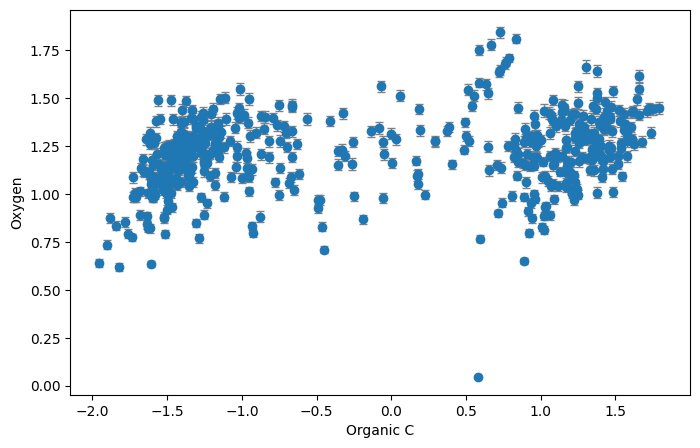

In [9]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.errorbar(
    avg['ac'], avg['O2'],
    xerr=err['ac'],   # x error values — adjust column name
    yerr=err['O2'],   # y error values — adjust column name
    fmt='o',          # marker style, mimics scatter
    ecolor='gray',
    elinewidth=1,
    capsize=3
)
#plt.plot([0,0], [-0.1,10], color='black', linestyle='dashed')
plt.xlabel('Organic C')
plt.ylabel('Oxygen')
#plt.ylim(-0.1, 4.3)
plt.show()

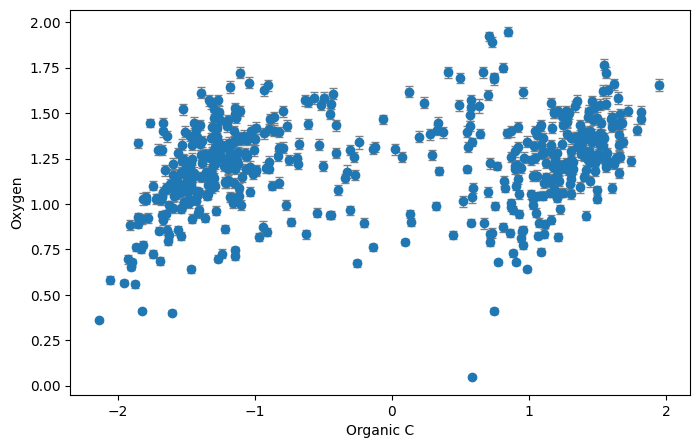

In [7]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.errorbar(
    avg2['ac'], avg2['O2'],
    xerr=err2['ac'],   # x error values — adjust column name
    yerr=err2['O2'],   # y error values — adjust column name
    fmt='o',          # marker style, mimics scatter
    ecolor='gray',
    elinewidth=1,
    capsize=3
)
#plt.plot([0,0], [-0.1,10], color='black', linestyle='dashed')
plt.xlabel('Organic C')
plt.ylabel('Oxygen')
#plt.ylim(-0.1, 4.3)
plt.show()

Text(0, 0.5, 'Growth')

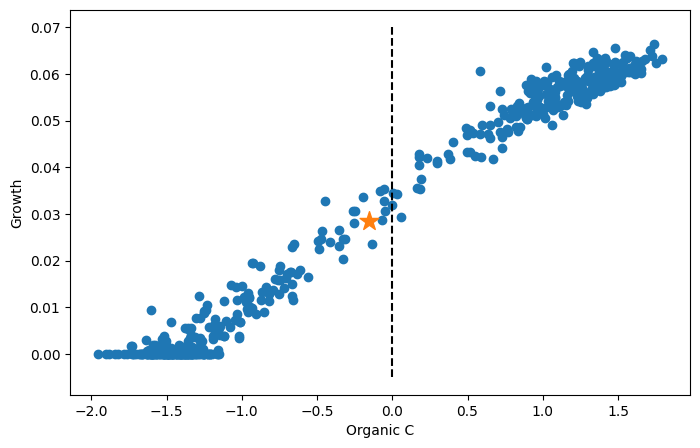

In [12]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.scatter(avg['ac'], avg['growth'])
plt.scatter([np.mean(avg['ac'])], [np.mean(avg['growth'])], marker='*', s=200)

plt.plot([0,0], [-0.005,0.07], color='black', linestyle='dashed')
plt.xlabel('Organic C')
plt.ylabel('Growth')
#plt.ylim(-0.005,0.07)

Text(0.5, 0, 'Growth')

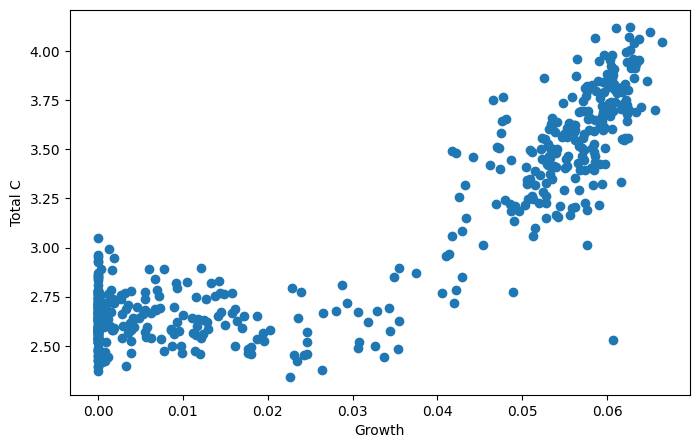

In [13]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.scatter(avg['growth'], avg['C']+np.array([max(0,i) for i in avg['ac']]))
#plt.scatter([np.mean(avg['C'])], [np.mean(avg['growth'])], marker='*', s=200)

#plt.plot([0,0], [-0.005,0.07], color='black', linestyle='dashed')
plt.ylabel('Total C')
plt.xlabel('Growth')
#plt.ylim(-0.005,0.07)

Text(0.5, 0, 'Growth')

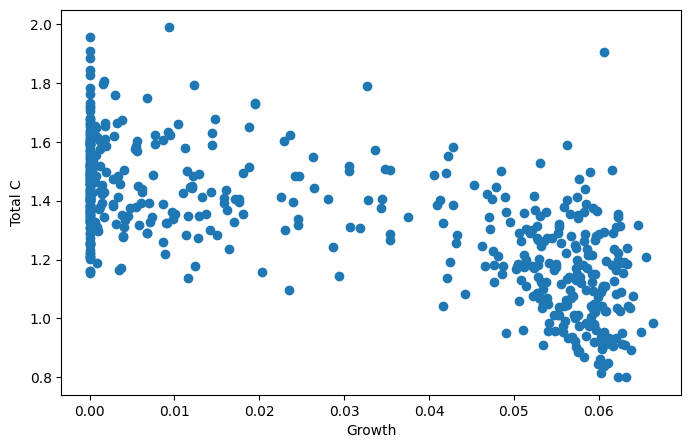

In [14]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.scatter(avg['growth'], avg['C']-avg['O2'])
#plt.scatter([np.mean(avg['C'])], [np.mean(avg['growth'])], marker='*', s=200)

#plt.plot([0,0], [-0.005,0.07], color='black', linestyle='dashed')
plt.ylabel('Total C')
plt.xlabel('Growth')
#plt.ylim(-0.005,0.07)

Text(0, 0.5, 'Yield')

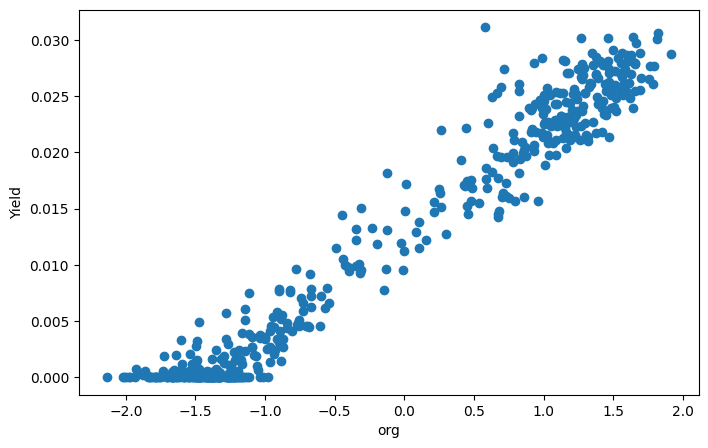

In [12]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.scatter(avg['ac'], avg['growth']/avg['C'])
#plt.scatter([np.mean(avg['C'])], [np.mean(avg['growth'])], marker='*', s=200)

#plt.plot([0,0], [-0.005,0.07], color='black', linestyle='dashed')
plt.xlabel('org')
plt.ylabel('Yield')
#plt.ylim(-0.005,0.07)

(-2.5, 2.0)

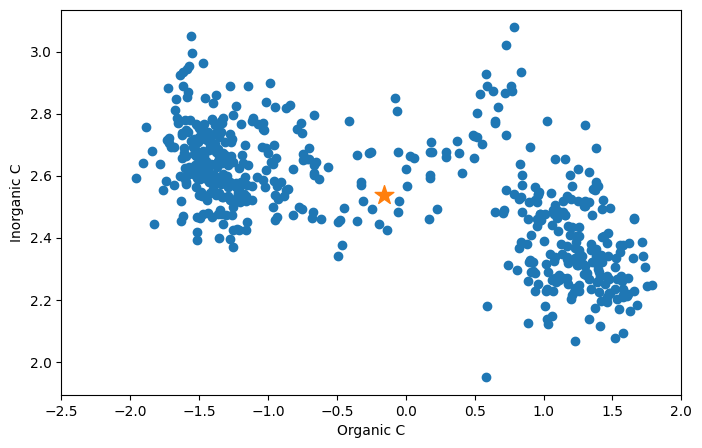

In [16]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.scatter(avg['ac'], avg['C'])
plt.scatter([np.mean(avg['ac'])], [np.mean(avg['C'])], marker='*', s=200)

#plt.plot([0,0], [-0.5,7.2], color='black', linestyle='dashed')
#plt.plot([-2.5,2],[0,0],  color='black', linestyle='dashed')

plt.xlabel('Organic C')
plt.ylabel('Inorganic C')
plt.xlim(-2.5,2)
#plt.ylim(-0.5,7.2)

Pearson r = -0.633, p = 1.662e-59
slope = -0.1002 ± 0.0054
intercept = 2.5215
R² = 0.400


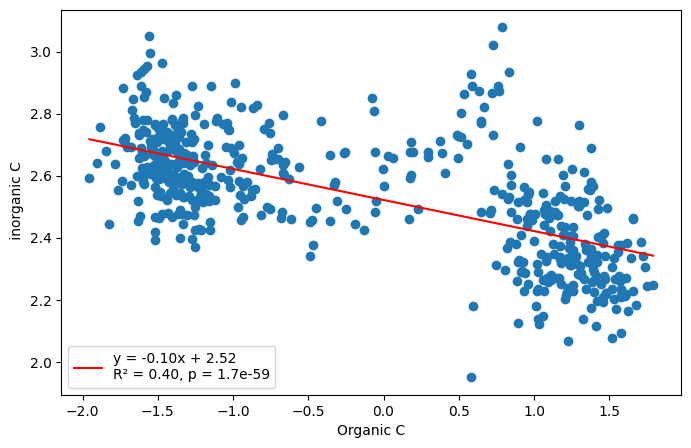

In [15]:
from scipy import stats
import numpy as np

# drop any rows where either column is NaN, so both arrays line up
mask = avg['ac'].notna() & avg['C'].notna()
x = avg.loc[mask, 'ac']
y = avg.loc[mask, 'C']

# Pearson correlation
r, p_value = stats.pearsonr(x, y)

# linear regression (least squares fit)
slope, intercept, r_value, p_value_reg, std_err = stats.linregress(x, y)

print(f"Pearson r = {r:.3f}, p = {p_value:.4g}")
print(f"slope = {slope:.4f} ± {std_err:.4f}")
print(f"intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.3f}")

plt.rcParams['figure.figsize'] = [8, 5]
plt.scatter(x, y)
xline = np.linspace(x.min(), x.max(), 100)
plt.plot(xline, slope*xline + intercept, color='red',
         label=f'y = {slope:.2f}x + {intercept:.2f}\nR² = {r_value**2:.2f}, p = {p_value:.2g}')
plt.xlabel('Organic C')
plt.ylabel(' inorganic C')
plt.legend()
plt.show()

(-0.5, 6.0)

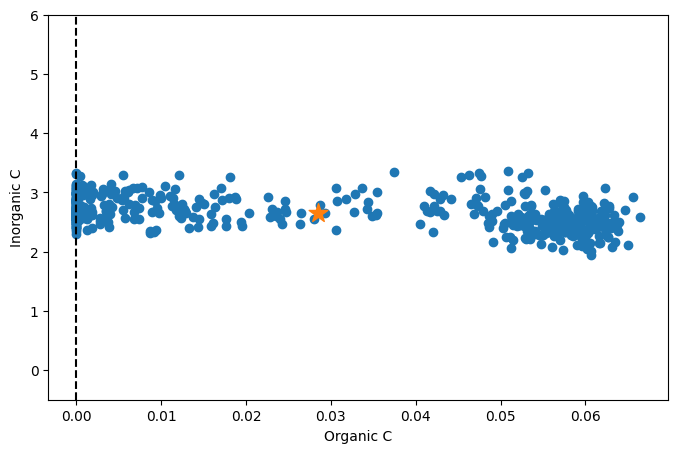

In [17]:
plt.rcParams['figure.figsize'] = [8, 5]
plt.scatter(avg['growth'], avg['C'])
plt.scatter([np.mean(avg['growth'])], [np.mean(avg['C'])], marker='*', s=200)

plt.plot([0,0], [-0.5,6], color='black', linestyle='dashed')
#plt.plot([-2.5,2],[0,0],  color='black', linestyle='dashed')

plt.xlabel('Organic C')
plt.ylabel('Inorganic C')
#plt.xlim(-2.5,2)
plt.ylim(-0.5,6)

In [13]:
np.mean(avg['C'])

np.float64(2.6130108721820533)

In [15]:
missing_aas = ['phe__L', 'asn__L', 'ile__L', 'met__L', 'thr__L', 'trp__L', 'tyr__L', 'val__L', 'cys__L', 'asp__L']
model = cobra.io.load_json_model('models/iJN678_std.json')

#aminoacids = ['glu__L', 'ala__L', 'gly',  'ser__L']
aminoacids = ['glu__L', 'ala__L', 'arg__L', 'gly', 'gln__L', 'his__L', 'leu__L','lys__L', 'pro__L', 'ser__L']

for aa in aminoacids:
    react = cobra.Reaction('EX_'+aa+'_p')
    mets = {model.metabolites.get_by_id(aa+'_c'):-1,model.metabolites.get_by_id(aa+'_p'):1 }
    react.add_metabolites(mets)
    react.lower_bound = 0
    react.upper_bound = 1000
    model.add_reactions([react])
    
for aa in missing_aas:
    # import (with ATP)
    m = cobra.Metabolite(aa+'_e', compartment='e', formula = model.metabolites.get_by_id(aa+'_c').formula)
    model.add_metabolites([m])
    
    r = cobra.Reaction('EX_'+aa+'_e')
    mets = {model.metabolites.get_by_id(aa+'_e'):-1}
    r.add_metabolites(mets)
    r.lower_bound = 0
    r.upper_bound = 1000
    
    r2 = cobra.Reaction(aa+'_trans')
    mets2 = {model.metabolites.get_by_id(aa+'_e'):-1, model.metabolites.atp_c:-1, model.metabolites.h2o_c:-1,
             model.metabolites.get_by_id(aa+'_c'):1, model.metabolites.adp_c:1, model.metabolites.h_c:1,
             model.metabolites.pi_c:1}
    r2.add_metabolites(mets2)
    r2.lower_bound = 0
    r2.upper_bound = 1000
    
    r3 = cobra.Reaction(aa+'_trans2')
    mets3 = {model.metabolites.get_by_id(aa+'_c'):-1, model.metabolites.get_by_id(aa+'_e'):1}
    r3.add_metabolites(mets3)
    r3.lower_bound = 0
    r3.upper_bound = 1000
    
    model.add_reactions([r,r2,r3])

    
met = cobra.Metabolite('lac__D_e', compartment='e', formula = model.metabolites.lac__D_c.formula)
model.add_metabolites(met)

ex_lac = cobra.Reaction('EX_lac__D_e')
mets = {model.metabolites.lac__D_c:-1}
ex_lac.add_metabolites(mets)
ex_lac.lower_bound = 0
ex_lac.upper_bound = 1000

trans_lac = cobra.Reaction('lac_trans')
mets = {model.metabolites.lac__D_e:-1, model.metabolites.h_p:-1, 
        model.metabolites.lac__D_c:1, model.metabolites.h_c:1}
trans_lac.add_metabolites(mets)
trans_lac.bounds = (-1000,1000)

model.add_reactions([ex_lac, trans_lac])

cobra.io.save_json_model(model, 'models/iJN678_std_aminoacids.json')

Set parameter Username
Set parameter LicenseID to value 2709761
Academic license - for non-commercial use only - expires 2026-09-17


In [19]:
# Sampling all cells  
import cobra
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
import os
from scipy import stats
from statsmodels.stats.multitest import  multipletests
import operator

avg = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat',sep='\t')
err = pd.read_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS.dat',sep='\t')


model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

acids_set = ['EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e', 'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e', 'EX_lac__D_e']
acids_c = [model.reactions.get_by_id(r).reactants[0].elements['C'] for r in acids_set]
   
    
aminoacids = ['glu__L', 'ala__L', 'arg__L', 'gly', 'gln__L', 'his__L', 'leu__L','lys__L', 'pro__L', 'ser__L', 
             'phe__L', 'asn__L', 'ile__L', 'met__L', 'thr__L', 'trp__L', 'tyr__L', 'val__L', 'cys__L', 'asp__L']
aminoacids_c = [model.metabolites.get_by_id(r+'_c').elements['C'] for r in aminoacids]
aminoacids_n =  [model.metabolites.get_by_id(r+'_c').elements['N'] for r in aminoacids]


i = 0

folder = 'results_new/genome_scale_samples_PEAKS/'

for cell in std[i:].iterrows():
    #if 'std_1000samples_cell'+str(i)+'.dat' not in os.listdir(folder):
    if True:
        print(i)
        c,n,g,sd = cell[1][2], cell[1][3], cell[1][4], cell[1][5]
        print(c,n,g, float(avg.iloc[i]['photons']), float(avg.iloc[i]['C']), float(avg.iloc[i]['O2']))

        model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')
        model.reactions.H2CO3_NAt_syn.bounds = (0,0)
        model.reactions.BCT1_syn.bounds = (float(avg.iloc[i]['C']-err.iloc[i]['C']),
                                            float(avg.iloc[i]['C']+err.iloc[i]['C']))
        model.reactions.EX_hco3_e.bounds = (-1000,0)
        model.reactions.EX_glc__D_e.lower_bound = 0
       # model.reactions.EX_hco3_e.bounds = (float(-avg.iloc[i]['C']-err.iloc[i]['C']),
       #                                     float(-avg.iloc[i]['C']+err.iloc[i]['C']))
        #model.reactions.EX_hco3_e.bounds = (-1000,0)
        #model.reactions.EX_co2_e.bounds = (float(avg.iloc[i]['O2']-err.iloc[i]['O2']),
        #                                   float(avg.iloc[i]['O2']+err.iloc[i]['O2']))
        #model.reactions.EX_nh4_e.bounds = (-1000,-avg.iloc[i]['n'])
        model.reactions.Diff_nh4_e.bounds = (0,1000)
     
        model.reactions.EX_photon_e.bounds = (float(-avg.iloc[i]['photons']-err.iloc[i]['photons']),
                                              float(-avg.iloc[i]['photons']+err.iloc[i]['photons']))
        
        model.reactions.EX_no3_e.lower_bound = 0
        model.reactions.EX_so4_e.lower_bound = -217
        #model.reactions.EX_nh4_e.bounds = (-n,-n)
        model.reactions.BIOMASS_Ec_SynAuto.bounds = (0,0)
        model.reactions.BIOMASS_Ec_SynHetero.bounds = (0,0)

        
        if avg.iloc[i]['ac']<0:
            for r in acids_set:
                model.reactions.get_by_id(r).bounds = (0, 1000)
            for aa in aminoacids:
                model.reactions.get_by_id('EX_'+aa+'_e').bounds = (0,1000)
        else: 
            for r in acids_set:
                model.reactions.get_by_id(r).bounds = (-1000,0)
            for aa in aminoacids:
                model.reactions.get_by_id('EX_'+aa+'_e').bounds = (-1000,0)
        
        lb = - avg.iloc[i]['ac']-err.iloc[i]['ac']
        #lb = -10
        ub = - avg.iloc[i]['ac']+err.iloc[i]['ac']
        print(lb)
        model.solver = 'glpk'

        sum_c_flux = model.problem.Constraint(
            acids_c[0]*model.reactions.get_by_id(acids_set[0]).flux_expression +
            acids_c[1]*model.reactions.get_by_id(acids_set[1]).flux_expression +
            acids_c[2]*model.reactions.get_by_id(acids_set[2]).flux_expression + 
            acids_c[3]*model.reactions.get_by_id(acids_set[3]).flux_expression + 
            acids_c[4]*model.reactions.get_by_id(acids_set[4]).flux_expression +
            acids_c[5]*model.reactions.get_by_id(acids_set[5]).flux_expression +
            acids_c[6]*model.reactions.get_by_id(acids_set[6]).flux_expression +
            acids_c[7]*model.reactions.get_by_id(acids_set[7]).flux_expression +
            aminoacids_c[0]*model.reactions.get_by_id('EX_'+aminoacids[0]+'_e').flux_expression +
            aminoacids_c[1]*model.reactions.get_by_id('EX_'+aminoacids[1]+'_e').flux_expression +
            aminoacids_c[2]*model.reactions.get_by_id('EX_'+aminoacids[2]+'_e').flux_expression +
            aminoacids_c[3]*model.reactions.get_by_id('EX_'+aminoacids[3]+'_e').flux_expression +
            aminoacids_c[4]*model.reactions.get_by_id('EX_'+aminoacids[4]+'_e').flux_expression +
            aminoacids_c[5]*model.reactions.get_by_id('EX_'+aminoacids[5]+'_e').flux_expression +
            aminoacids_c[6]*model.reactions.get_by_id('EX_'+aminoacids[6]+'_e').flux_expression +
            aminoacids_c[7]*model.reactions.get_by_id('EX_'+aminoacids[7]+'_e').flux_expression +
            aminoacids_c[8]*model.reactions.get_by_id('EX_'+aminoacids[8]+'_e').flux_expression +
            aminoacids_c[9]*model.reactions.get_by_id('EX_'+aminoacids[9]+'_e').flux_expression +
            aminoacids_c[10]*model.reactions.get_by_id('EX_'+aminoacids[10]+'_e').flux_expression +
            aminoacids_c[11]*model.reactions.get_by_id('EX_'+aminoacids[11]+'_e').flux_expression +
            aminoacids_c[12]*model.reactions.get_by_id('EX_'+aminoacids[12]+'_e').flux_expression +
            aminoacids_c[13]*model.reactions.get_by_id('EX_'+aminoacids[13]+'_e').flux_expression +
            aminoacids_c[14]*model.reactions.get_by_id('EX_'+aminoacids[14]+'_e').flux_expression +
            aminoacids_c[15]*model.reactions.get_by_id('EX_'+aminoacids[15]+'_e').flux_expression +
            aminoacids_c[16]*model.reactions.get_by_id('EX_'+aminoacids[16]+'_e').flux_expression +
            aminoacids_c[17]*model.reactions.get_by_id('EX_'+aminoacids[17]+'_e').flux_expression +
            aminoacids_c[18]*model.reactions.get_by_id('EX_'+aminoacids[18]+'_e').flux_expression +
            aminoacids_c[19]*model.reactions.get_by_id('EX_'+aminoacids[19]+'_e').flux_expression,
            lb=lb,
            ub=ub)
        model.add_cons_vars(sum_c_flux)
        

        lb = - 1000
        ub = - avg.iloc[i]['n']
        
        sum_n_flux = model.problem.Constraint(
            model.reactions.EX_nh4_e.flux_expression + 
            aminoacids_n[0]*model.reactions.get_by_id('EX_'+aminoacids[0]+'_e').flux_expression +
            aminoacids_n[1]*model.reactions.get_by_id('EX_'+aminoacids[1]+'_e').flux_expression +
            aminoacids_n[2]*model.reactions.get_by_id('EX_'+aminoacids[2]+'_e').flux_expression +
            aminoacids_n[3]*model.reactions.get_by_id('EX_'+aminoacids[3]+'_e').flux_expression +
            aminoacids_n[4]*model.reactions.get_by_id('EX_'+aminoacids[4]+'_e').flux_expression +
            aminoacids_n[5]*model.reactions.get_by_id('EX_'+aminoacids[5]+'_e').flux_expression +
            aminoacids_n[6]*model.reactions.get_by_id('EX_'+aminoacids[6]+'_e').flux_expression +
            aminoacids_n[7]*model.reactions.get_by_id('EX_'+aminoacids[7]+'_e').flux_expression +
            aminoacids_n[8]*model.reactions.get_by_id('EX_'+aminoacids[8]+'_e').flux_expression +
            aminoacids_n[9]*model.reactions.get_by_id('EX_'+aminoacids[9]+'_e').flux_expression +
            aminoacids_n[10]*model.reactions.get_by_id('EX_'+aminoacids[10]+'_e').flux_expression +
            aminoacids_n[11]*model.reactions.get_by_id('EX_'+aminoacids[11]+'_e').flux_expression +
            aminoacids_n[12]*model.reactions.get_by_id('EX_'+aminoacids[12]+'_e').flux_expression +
            aminoacids_n[13]*model.reactions.get_by_id('EX_'+aminoacids[13]+'_e').flux_expression +
            aminoacids_n[14]*model.reactions.get_by_id('EX_'+aminoacids[14]+'_e').flux_expression +
            aminoacids_n[15]*model.reactions.get_by_id('EX_'+aminoacids[15]+'_e').flux_expression +
            aminoacids_n[16]*model.reactions.get_by_id('EX_'+aminoacids[16]+'_e').flux_expression +
            aminoacids_n[17]*model.reactions.get_by_id('EX_'+aminoacids[17]+'_e').flux_expression +
            aminoacids_n[18]*model.reactions.get_by_id('EX_'+aminoacids[18]+'_e').flux_expression +
            aminoacids_n[19]*model.reactions.get_by_id('EX_'+aminoacids[19]+'_e').flux_expression,
            lb=lb,
            ub=ub)
        model.add_cons_vars(sum_n_flux)
        
        model.reactions.BIOMASS_Ec_SynMixo.bounds = (g-sd,g+sd)


        try: 
            a = cobra.sampling.sample(model, n = 1000 , processes=4)
            #display(a)
            a.to_csv('results_new/genome_scale_samples_PEAKS/std_1000samples_cell'+str(i)+'.dat', index=None, sep='\t')
        except: 
            print('not feasible')
            pass

    i += 1
    

    
    # 70 90 124 155 164 189 214 279 288 371 374 417 501 568 621 632 643 641 669 689 717

0
2.519806476997647 0.826899672424375 0.0606526677320321 22.99169863774345 1.953288492228392 0.046988520163249


/tmp/ipykernel_5914/3523869793.py:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  c,n,g,sd = cell[1][2], cell[1][3], cell[1][4], cell[1][5]


-0.5805328801871198


hopsy is not available in your environment.Falling back to 'optgp' sampler.
Exception ignored in: <built-in method acquire of _thread.lock object at 0x7584782d5940>
Traceback (most recent call last):
  File "/usr/lib/python3.10/multiprocessing/popen_fork.py", line 66, in _launch
    self.pid = os.fork()
KeyboardInterrupt: 
Process ForkPoolWorker-23:
Process ForkPoolWorker-25:
Process ForkPoolWorker-24:
Process ForkPoolWorker-26:
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/usr/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/usr/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/lib/python3.10/multiprocessing/pool.py", line 125, i

not feasible
1
2.341554308132727 0.926153415925802 0.0562490409221232 22.0903554030257 2.2743590367652917 0.613939914460877


KeyboardInterrupt: 

In [ ]:
model.reactions.BIOMASS_Ec_SynMixo.metabolites

In [16]:


import statistics as st


#clusters = pd.read_csv('results/cluster_labels_std.dat', header=None)
clusters = pd.read_csv('results/4_clusters.dat', header=None)
cluster_ids = {}
for i in range(0,4):
    cluster_ids['cluster'+str(i+1)] = list(clusters[clusters[0]==i].index)
    
mean_dfs = []
std_dfs = []
mode_dfs = []
for cluster in cluster_ids:
    means = {}
    stds = {}
    modes = {}
    for i in cluster_ids[cluster]:
        file = 'std_1000samples_cell'+str(i)+'.dat'
        directory = 'results/sampling_with_exchange/std_avg_corrected_err_prop/'
        if file in os.listdir(directory):
            sample = pd.read_csv(directory+file, sep ='\t')
            print(file)
            for r in sample: 
                if r not in means: 
                    means[r] = [np.mean(sample[r])]
                    stds[r] = [np.std(sample[r])]
                    modes[r] = [st.mode(sample[r])]
                else:
                    means[r].append(np.mean(sample[r]))
                    stds[r].append(np.std(sample[r]))
                    modes[r].append(st.mode(sample[r]))
    mean_dfs.append(pd.DataFrame(means))
    std_dfs.append(pd.DataFrame(stds))
    mode_dfs.append(pd.DataFrame(modes))

std_1000samples_cell142.dat
std_1000samples_cell152.dat
std_1000samples_cell335.dat
std_1000samples_cell471.dat
std_1000samples_cell501.dat
std_1000samples_cell528.dat
std_1000samples_cell529.dat
std_1000samples_cell598.dat
std_1000samples_cell619.dat
std_1000samples_cell0.dat
std_1000samples_cell1.dat
std_1000samples_cell2.dat
std_1000samples_cell3.dat
std_1000samples_cell4.dat
std_1000samples_cell5.dat
std_1000samples_cell6.dat
std_1000samples_cell7.dat
std_1000samples_cell8.dat
std_1000samples_cell9.dat
std_1000samples_cell10.dat
std_1000samples_cell11.dat
std_1000samples_cell12.dat
std_1000samples_cell13.dat
std_1000samples_cell14.dat
std_1000samples_cell15.dat
std_1000samples_cell16.dat
std_1000samples_cell17.dat
std_1000samples_cell18.dat
std_1000samples_cell19.dat
std_1000samples_cell20.dat
std_1000samples_cell21.dat
std_1000samples_cell22.dat
std_1000samples_cell23.dat
std_1000samples_cell24.dat
std_1000samples_cell25.dat
std_1000samples_cell26.dat
std_1000samples_cell27.dat
st

std_1000samples_cell337.dat
std_1000samples_cell338.dat
std_1000samples_cell339.dat
std_1000samples_cell340.dat
std_1000samples_cell341.dat
std_1000samples_cell342.dat
std_1000samples_cell343.dat
std_1000samples_cell344.dat
std_1000samples_cell345.dat
std_1000samples_cell346.dat
std_1000samples_cell347.dat
std_1000samples_cell348.dat
std_1000samples_cell349.dat
std_1000samples_cell350.dat
std_1000samples_cell351.dat
std_1000samples_cell352.dat
std_1000samples_cell353.dat
std_1000samples_cell354.dat
std_1000samples_cell355.dat
std_1000samples_cell356.dat
std_1000samples_cell357.dat
std_1000samples_cell358.dat
std_1000samples_cell359.dat
std_1000samples_cell360.dat
std_1000samples_cell361.dat
std_1000samples_cell362.dat
std_1000samples_cell363.dat
std_1000samples_cell364.dat
std_1000samples_cell365.dat
std_1000samples_cell366.dat
std_1000samples_cell367.dat
std_1000samples_cell368.dat
std_1000samples_cell369.dat
std_1000samples_cell370.dat
std_1000samples_cell371.dat
std_1000samples_cell

std_1000samples_cell641.dat
std_1000samples_cell642.dat
std_1000samples_cell643.dat
std_1000samples_cell644.dat
std_1000samples_cell645.dat
std_1000samples_cell646.dat
std_1000samples_cell647.dat
std_1000samples_cell648.dat
std_1000samples_cell649.dat
std_1000samples_cell650.dat
std_1000samples_cell651.dat
std_1000samples_cell652.dat
std_1000samples_cell653.dat
std_1000samples_cell654.dat
std_1000samples_cell655.dat
std_1000samples_cell656.dat
std_1000samples_cell657.dat
std_1000samples_cell658.dat
std_1000samples_cell659.dat
std_1000samples_cell660.dat
std_1000samples_cell661.dat
std_1000samples_cell662.dat
std_1000samples_cell663.dat
std_1000samples_cell664.dat
std_1000samples_cell665.dat
std_1000samples_cell666.dat
std_1000samples_cell667.dat
std_1000samples_cell668.dat
std_1000samples_cell669.dat
std_1000samples_cell670.dat
std_1000samples_cell671.dat
std_1000samples_cell672.dat
std_1000samples_cell673.dat
std_1000samples_cell674.dat
std_1000samples_cell675.dat
std_1000samples_cell

In [17]:
all_means = pd.concat(mean_dfs)

In [18]:
#all_means.to_csv('results/sampling_with_exchange/std_sampling_exchange_averages_avg_new.dat', sep='\t', index=False)
#all_means.to_csv('results/sampling_with_exchange/std_sampling_exchange_averages_avg.dat', sep='\t', index=False)
all_means.to_csv('results/sampling_with_exchange/std_sampling_exchange_averages_avg_corrected_err_prop.dat', sep='\t', index=False)

